In [1]:

import os
import random
import numpy as np
import pandas as pd
import torch
import torchvision
from pathlib import Path

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Project paths
PROJECT_DIR = Path.cwd().parent

DATASET_DIR = (
    PROJECT_DIR / "notebooks" / "dataset" / "processed_dataset"
)

PREPROCESSING_DIR = (
    PROJECT_DIR / "notebooks" / "research-notes" / "preprocessing"
)

MODEL_DIR = PROJECT_DIR / "models" / "densenet121"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PROJECT DIRECTORY:", PROJECT_DIR)
print("DATASET DIRECTORY:", DATASET_DIR)
print("MODEL DIRECTORY:", MODEL_DIR)

print("\nPyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )

# Dataset verification
COLOR_SPACES = ["RGB", "HSV", "YCgCr"]
SPLITS = ["train", "validation", "test"]
CLASS_NAMES = ["Ripe", "Unripe"]

for color_space in COLOR_SPACES:
    print(f"\n{color_space}")

    for split in SPLITS:
        split_path = DATASET_DIR / color_space / split

        counts = {
            cls: len(list((split_path / cls).glob("*.png")))
            for cls in CLASS_NAMES
        }

        print(split, counts, "Total:", sum(counts.values()))

print("\nEnvironment and dataset verification completed.")


PROJECT DIRECTORY: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter
DATASET DIRECTORY: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\notebooks\dataset\processed_dataset
MODEL DIRECTORY: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\models\densenet121

PyTorch: 2.15.0+cu132
Torchvision: 0.29.2+cu132
CUDA available: True
Device: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
GPU memory: 8.0 GB

RGB
train {'Ripe': 204, 'Unripe': 354} Total: 558
validation {'Ripe': 25, 'Unripe': 44} Total: 69
test {'Ripe': 26, 'Unripe': 44} Total: 70

HSV
train {'Ripe': 204, 'Unripe': 354} Total: 558
validation {'Ripe': 25, 'Unripe': 44} Total: 69
test {'Ripe': 26, 'Unripe': 44} Total: 70

YCgCr
train {'Ripe': 204, 'Unripe': 354} Total: 558
validation {'Ripe': 25, 'Unripe': 44} Total: 69
test {'Ripe': 26, 'Unripe': 44} Total: 70

Environment and dataset verification completed.


In [2]:

# ============================================================
# DENSENET121 CONFIGURATION
# ============================================================

SEED = 42

IMAGE_SIZE = 224
BATCH_SIZE = 16
NUM_CLASSES = 2

NUM_EPOCHS_HEAD = 10
NUM_EPOCHS_FINETUNE = 40
TOTAL_MAX_EPOCHS = 50

LEARNING_RATE_HEAD = 1e-3
LEARNING_RATE_FINETUNE = 1e-4

WEIGHT_DECAY = 1e-4
EARLY_STOPPING_PATIENCE = 5

COLOR_SPACES = ["RGB", "HSV", "YCgCr"]
CLASS_NAMES = ["Ripe", "Unripe"]

# Reproducibility
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Save experiment configuration
import json

CONFIG = {
    "model": "DenseNet121",
    "seed": SEED,
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "num_classes": NUM_CLASSES,
    "epochs_head": NUM_EPOCHS_HEAD,
    "epochs_finetune": NUM_EPOCHS_FINETUNE,
    "learning_rate_head": LEARNING_RATE_HEAD,
    "learning_rate_finetune": LEARNING_RATE_FINETUNE,
    "weight_decay": WEIGHT_DECAY,
    "early_stopping_patience": EARLY_STOPPING_PATIENCE,
    "color_spaces": COLOR_SPACES,
    "classes": CLASS_NAMES
}

with open(MODEL_DIR / "densenet121_config.json", "w") as f:
    json.dump(CONFIG, f, indent=4)

print("DenseNet121 configuration saved.")
print(json.dumps(CONFIG, indent=4))


DenseNet121 configuration saved.
{
    "model": "DenseNet121",
    "seed": 42,
    "image_size": 224,
    "batch_size": 16,
    "num_classes": 2,
    "epochs_head": 10,
    "epochs_finetune": 40,
    "learning_rate_head": 0.001,
    "learning_rate_finetune": 0.0001,
    "weight_decay": 0.0001,
    "early_stopping_patience": 5,
    "color_spaces": [
        "RGB",
        "HSV",
        "YCgCr"
    ],
    "classes": [
        "Ripe",
        "Unripe"
    ]
}


In [3]:

import json

stats_path = PREPROCESSING_DIR / "normalization_stats.json"

with open(stats_path, "r") as f:
    normalization_stats = json.load(f)

for color_space in COLOR_SPACES:
    print(f"\n{color_space}")
    print("Mean:", normalization_stats[color_space]["mean"])
    print("Std :", normalization_stats[color_space]["std"])



RGB
Mean: [0.3409183707365453, 0.31965236125256286, 0.246347647622037]
Std : [0.3073407603064623, 0.2990722908867604, 0.2818262994987366]

HSV
Mean: [0.1791005163545884, 0.2921350788579354, 0.3535657906756214]
Std : [0.23581772780670712, 0.28432641901263034, 0.31211639141326053]

YCgCr
Mean: [0.30671704291596547, 0.5135682372747012, 0.5478768622983937]
Std : [0.29169941609069794, 0.026401596916654203, 0.06957786056603277]


In [4]:

import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

# ============================================================
# TRANSFORMS
# ============================================================

data_transforms = {}

for color_space in COLOR_SPACES:

    mean = normalization_stats[color_space]["mean"]
    std = normalization_stats[color_space]["std"]

    data_transforms[color_space] = {
        "train": transforms.Compose([
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomRotation(
                degrees=10,
                interpolation=transforms.InterpolationMode.BILINEAR,
                fill=tuple(int(x * 255) for x in mean)
            ),
            transforms.ToTensor(),
            transforms.Normalize(mean=mean, std=std)
        ]),

        "validation": transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize(mean=mean, std=std)
        ]),

        "test": transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize(mean=mean, std=std)
        ])
    }


# ============================================================
# DATASETS AND DATALOADERS
# ============================================================

datasets_dict = {}
dataloaders = {}

for color_space in COLOR_SPACES:

    datasets_dict[color_space] = {}
    dataloaders[color_space] = {}

    for split in SPLITS:

        dataset_path = DATASET_DIR / color_space / split

        datasets_dict[color_space][split] = datasets.ImageFolder(
            root=dataset_path,
            transform=data_transforms[color_space][split]
        )

        dataloaders[color_space][split] = DataLoader(
            datasets_dict[color_space][split],
            batch_size=BATCH_SIZE,
            shuffle=(split == "train"),
            num_workers=0,
            pin_memory=torch.cuda.is_available()
        )

    print(f"\n{color_space}")
    for split in SPLITS:
        print(
            f"{split}:",
            len(datasets_dict[color_space][split]),
            "images"
        )

    print(
        "Class mapping:",
        datasets_dict[color_space]["train"].class_to_idx
    )


# ============================================================
# BATCH VERIFICATION
# ============================================================

for color_space in COLOR_SPACES:

    images, labels = next(iter(dataloaders[color_space]["train"]))

    print(f"\n{color_space} batch verification")
    print("Image shape:", images.shape)
    print("Label shape:", labels.shape)
    print("Image dtype:", images.dtype)
    print("Label dtype:", labels.dtype)

print("\nAll DenseNet121 dataloaders created successfully.")



RGB
train: 558 images
validation: 69 images
test: 70 images
Class mapping: {'Ripe': 0, 'Unripe': 1}

HSV
train: 558 images
validation: 69 images
test: 70 images
Class mapping: {'Ripe': 0, 'Unripe': 1}

YCgCr
train: 558 images
validation: 69 images
test: 70 images
Class mapping: {'Ripe': 0, 'Unripe': 1}

RGB batch verification
Image shape: torch.Size([16, 3, 224, 224])
Label shape: torch.Size([16])
Image dtype: torch.float32
Label dtype: torch.int64

HSV batch verification
Image shape: torch.Size([16, 3, 224, 224])
Label shape: torch.Size([16])
Image dtype: torch.float32
Label dtype: torch.int64

YCgCr batch verification
Image shape: torch.Size([16, 3, 224, 224])
Label shape: torch.Size([16])
Image dtype: torch.float32
Label dtype: torch.int64

All DenseNet121 dataloaders created successfully.


In [5]:

import torch.nn as nn
from torchvision.models import densenet121, DenseNet121_Weights

def build_densenet121(num_classes=2):

    model = densenet121(
        weights=DenseNet121_Weights.IMAGENET1K_V1
    )

    # Freeze the complete feature extractor initially
    for param in model.features.parameters():
        param.requires_grad = False

    # Replace classification layer
    in_features = model.classifier.in_features

    model.classifier = nn.Linear(
        in_features,
        num_classes
    )

    return model


# Initialize model
model = build_densenet121(NUM_CLASSES).to(DEVICE)

print(model.classifier)
print("\nModel architecture:", model.__class__.__name__)

print(
    "\nTotal parameters:",
    sum(p.numel() for p in model.parameters())
)

print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)

print(
    "Frozen parameters:",
    sum(p.numel() for p in model.parameters() if not p.requires_grad)
)


Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to C:\Users\gsama/.cache\torch\hub\checkpoints\densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:04<00:00, 7.64MB/s]


Linear(in_features=1024, out_features=2, bias=True)

Model architecture: DenseNet

Total parameters: 6955906
Trainable parameters: 2050
Frozen parameters: 6953856


In [7]:

import copy
import time
from sklearn.metrics import accuracy_score, f1_score

criterion = nn.CrossEntropyLoss()


def set_batchnorm_eval(model):
    """Keep BatchNorm layers in evaluation mode."""
    for module in model.modules():
        if isinstance(module, nn.BatchNorm2d):
            module.eval()


def run_epoch(model, loader, optimizer=None):

    training = optimizer is not None
    model.train(training)

    if training:
        set_batchnorm_eval(model)

    running_loss = 0.0
    all_labels = []
    all_predictions = []

    for images, labels in loader:

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):

            outputs = model(images)
            loss = criterion(outputs, labels)

            if training:
                loss.backward()
                optimizer.step()

        predictions = torch.argmax(outputs, dim=1)

        running_loss += loss.item() * images.size(0)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)

    epoch_accuracy = accuracy_score(
        all_labels, all_predictions
    )

    epoch_macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return {
        "loss": epoch_loss,
        "accuracy": epoch_accuracy,
        "macro_f1": epoch_macro_f1
    }


def train_model(
    model,
    train_loader,
    val_loader,
    color_space,
    phase,
    max_epochs,
    learning_rate,
    checkpoint_path
):

    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=learning_rate,
        weight_decay=WEIGHT_DECAY
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=2,
        min_lr=1e-7
    )

    best_val_loss = float("inf")
    best_state = None
    best_epoch = None
    patience_counter = 0

    history = []

    start_time = time.time()

    for epoch in range(max_epochs):

        train_metrics = run_epoch(
            model, train_loader, optimizer
        )

        val_metrics = run_epoch(
            model, val_loader
        )

        scheduler.step(val_metrics["loss"])

        current_lr = optimizer.param_groups[0]["lr"]

        record = {
            "phase": phase,
            "epoch": epoch + 1,
            "train_loss": train_metrics["loss"],
            "train_accuracy": train_metrics["accuracy"],
            "train_macro_f1": train_metrics["macro_f1"],
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "val_macro_f1": val_metrics["macro_f1"],
            "learning_rate": current_lr
        }

        history.append(record)

        print(
            f"{color_space} | {phase} | "
            f"Epoch {epoch + 1}/{max_epochs} | "
            f"Train Loss: {train_metrics['loss']:.4f} | "
            f"Train Acc: {train_metrics['accuracy']:.4f} | "
            f"Val Loss: {val_metrics['loss']:.4f} | "
            f"Val Acc: {val_metrics['accuracy']:.4f} | "
            f"Val Macro F1: {val_metrics['macro_f1']:.4f}"
        )

        if val_metrics["loss"] < best_val_loss:

            best_val_loss = val_metrics["loss"]
            best_epoch = epoch + 1
            best_state = copy.deepcopy(model.state_dict())
            patience_counter = 0

            torch.save({
                "model_state_dict": best_state,
                "best_epoch": best_epoch,
                "best_val_loss": best_val_loss,
                "color_space": color_space,
                "phase": phase
            }, checkpoint_path)

        else:
            patience_counter += 1

        if patience_counter >= EARLY_STOPPING_PATIENCE:
            print("Early stopping triggered.")
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    elapsed = (time.time() - start_time) / 60

    print(
        f"\n{color_space} | {phase} completed | "
        f"Best epoch: {best_epoch} | "
        f"Best validation loss: {best_val_loss:.4f} | "
        f"Time: {elapsed:.2f} minutes"
    )

    return model, history


In [8]:

def configure_finetuning(model):

    # Freeze the complete feature extractor
    for param in model.features.parameters():
        param.requires_grad = False

    # Unfreeze final transition and dense block
    for param in model.features.transition3.parameters():
        param.requires_grad = True

    for param in model.features.denseblock4.parameters():
        param.requires_grad = True

    # Keep classifier trainable
    for param in model.classifier.parameters():
        param.requires_grad = True

    # Keep BatchNorm parameters frozen
    for module in model.features.modules():
        if isinstance(module, nn.BatchNorm2d):
            for param in module.parameters():
                param.requires_grad = False

    trainable = sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )

    frozen = sum(
        p.numel() for p in model.parameters()
        if not p.requires_grad
    )

    print("Fine-tuning configuration:")
    print("Trainable parameters:", trainable)
    print("Frozen parameters:", frozen)

    return model


print("Fine-tuning function defined successfully.")


Fine-tuning function defined successfully.


In [9]:

def run_densenet_experiment(color_space):

    print("\n" + "=" * 65)
    print(f"STARTING DENSENET121 EXPERIMENT: {color_space}")
    print("=" * 65)

    # Initialize a fresh pretrained model for each color space
    model = build_densenet121(NUM_CLASSES).to(DEVICE)

    train_loader = dataloaders[color_space]["train"]
    val_loader = dataloaders[color_space]["validation"]

    phase1_path = MODEL_DIR / f"densenet121_{color_space}_phase1.pth"
    phase2_path = MODEL_DIR / f"densenet121_{color_space}_phase2.pth"
    final_path = MODEL_DIR / f"densenet121_{color_space}_best.pth"

    # ---------------- PHASE 1 ----------------
    print("\nPHASE 1: TRAIN CLASSIFIER")

    model, history1 = train_model(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        color_space=color_space,
        phase="Phase 1",
        max_epochs=NUM_EPOCHS_HEAD,
        learning_rate=LEARNING_RATE_HEAD,
        checkpoint_path=phase1_path
    )

    phase1_best = torch.load(
        phase1_path,
        map_location=DEVICE,
        weights_only=False
    )

    best_overall_state = copy.deepcopy(
        phase1_best["model_state_dict"]
    )

    best_overall_loss = phase1_best["best_val_loss"]
    best_overall_epoch = phase1_best["best_epoch"]
    best_overall_phase = "Phase 1"

    # ---------------- PHASE 2 ----------------
    print("\nPHASE 2: FINE-TUNING")

    model = configure_finetuning(model)

    model, history2 = train_model(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        color_space=color_space,
        phase="Phase 2",
        max_epochs=NUM_EPOCHS_FINETUNE,
        learning_rate=LEARNING_RATE_FINETUNE,
        checkpoint_path=phase2_path
    )

    phase2_best = torch.load(
        phase2_path,
        map_location=DEVICE,
        weights_only=False
    )

    if phase2_best["best_val_loss"] < best_overall_loss:

        best_overall_state = copy.deepcopy(
            phase2_best["model_state_dict"]
        )

        best_overall_loss = phase2_best["best_val_loss"]
        best_overall_epoch = phase2_best["best_epoch"]
        best_overall_phase = "Phase 2"

    # Restore best checkpoint across both phases
    model.load_state_dict(best_overall_state)

    torch.save({
        "model_state_dict": best_overall_state,
        "best_val_loss": best_overall_loss,
        "best_epoch": best_overall_epoch,
        "best_phase": best_overall_phase,
        "color_space": color_space
    }, final_path)

    # Combine histories using actual epoch numbering
    history1_df = pd.DataFrame(history1)
    history2_df = pd.DataFrame(history2)

    history2_df["epoch"] += len(history1_df)

    combined_history = pd.concat(
        [history1_df, history2_df],
        ignore_index=True
    )

    combined_history.to_csv(
        MODEL_DIR / f"densenet121_{color_space}_history.csv",
        index=False
    )

    print("\nEXPERIMENT COMPLETED")
    print("Color space:", color_space)
    print("Best phase:", best_overall_phase)
    print("Best epoch:", best_overall_epoch)
    print("Best validation loss:", round(best_overall_loss, 4))
    print("Checkpoint:", final_path)

    return model, combined_history


print("DenseNet121 experiment runner defined successfully.")


DenseNet121 experiment runner defined successfully.


In [11]:

# ============================================================
# DENSENET121 — RGB EXPERIMENT
# ============================================================

rgb_model, rgb_history = run_densenet_experiment("RGB")

print("\nRGB experiment history:")
display(rgb_history.tail(5))

print("\nRGB best validation loss:",
      rgb_history["val_loss"].min())

print("RGB best validation accuracy:",
      rgb_history["val_accuracy"].max())



STARTING DENSENET121 EXPERIMENT: RGB

PHASE 1: TRAIN CLASSIFIER
RGB | Phase 1 | Epoch 1/10 | Train Loss: 0.5482 | Train Acc: 0.7025 | Val Loss: 0.4116 | Val Acc: 0.8116 | Val Macro F1: 0.7943
RGB | Phase 1 | Epoch 2/10 | Train Loss: 0.4147 | Train Acc: 0.8208 | Val Loss: 0.3578 | Val Acc: 0.8116 | Val Macro F1: 0.7943
RGB | Phase 1 | Epoch 3/10 | Train Loss: 0.3789 | Train Acc: 0.8584 | Val Loss: 0.4186 | Val Acc: 0.8116 | Val Macro F1: 0.8076
RGB | Phase 1 | Epoch 4/10 | Train Loss: 0.3805 | Train Acc: 0.8351 | Val Loss: 0.3435 | Val Acc: 0.8261 | Val Macro F1: 0.8175
RGB | Phase 1 | Epoch 5/10 | Train Loss: 0.3693 | Train Acc: 0.8423 | Val Loss: 0.3376 | Val Acc: 0.8261 | Val Macro F1: 0.8175
RGB | Phase 1 | Epoch 6/10 | Train Loss: 0.3346 | Train Acc: 0.8602 | Val Loss: 0.3349 | Val Acc: 0.8261 | Val Macro F1: 0.8175
RGB | Phase 1 | Epoch 7/10 | Train Loss: 0.3384 | Train Acc: 0.8602 | Val Loss: 0.3183 | Val Acc: 0.8841 | Val Macro F1: 0.8696
RGB | Phase 1 | Epoch 8/10 | Train Loss

,phase,epoch,train_loss,train_accuracy,train_macro_f1,val_loss,val_accuracy,val_macro_f1,learning_rate
14,Phase 2,15,0.185506,0.917563,0.909768,0.314239,0.884058,0.879791,0.00010
15,Phase 2,16,0.158835,0.933692,0.927670,0.419266,0.855072,0.852564,0.00010
16,Phase 2,17,0.127099,0.956989,0.953443,0.352849,0.884058,0.881034,0.00005
17,Phase 2,18,0.059676,0.985663,0.984448,0.290723,0.927536,0.922245,0.00005
18,Phase 2,19,0.049640,0.980287,0.978592,0.482765,0.840580,0.837159,0.00005



RGB best validation loss: 0.21761661951524625
RGB best validation accuracy: 0.927536231884058


In [12]:

# ============================================================
# RGB CHECKPOINT AND HISTORY CONSISTENCY CHECK
# ============================================================

rgb_history = pd.read_csv(
    MODEL_DIR / "densenet121_RGB_history.csv"
)

checkpoint = torch.load(
    MODEL_DIR / "densenet121_RGB_best.pth",
    map_location="cpu",
    weights_only=False
)

print("HISTORY ROWS:", len(rgb_history))

print("\nMinimum validation loss in history:")
print(rgb_history["val_loss"].min())

print("\nRows containing minimum validation loss:")
display(
    rgb_history[
        rgb_history["val_loss"] ==
        rgb_history["val_loss"].min()
    ]
)

print("\nBest validation loss recorded in final checkpoint:")
print(checkpoint["best_val_loss"])

print("\nCheckpoint best epoch:")
print(checkpoint["best_epoch"])

print("\nCheckpoint best phase:")
print(checkpoint["best_phase"])

print("\nPhase-wise minimum validation loss:")
display(
    rgb_history.groupby("phase")["val_loss"].min()
)


HISTORY ROWS: 19

Minimum validation loss in history:
0.21761661951524625

Rows containing minimum validation loss:


,phase,epoch,train_loss,train_accuracy,train_macro_f1,val_loss,val_accuracy,val_macro_f1,learning_rate
13,Phase 2,14,0.208994,0.922939,0.916129,0.217617,0.898551,0.88707,0.0001



Best validation loss recorded in final checkpoint:
0.21761661951524625

Checkpoint best epoch:
4

Checkpoint best phase:
Phase 2

Phase-wise minimum validation loss:


phase
Phase 1    0.299897
Phase 2    0.217617
Name: val_loss, dtype: float64

In [13]:

print("IN-MEMORY HISTORY")
print("Rows:", len(rgb_history))
print("Minimum validation loss:", rgb_history["val_loss"].min())

print("\nSAVED CSV HISTORY")
saved_rgb_history = pd.read_csv(
    MODEL_DIR / "densenet121_RGB_history.csv"
)
print("Rows:", len(saved_rgb_history))
print("Minimum validation loss:", saved_rgb_history["val_loss"].min())

print("\nCHECKPOINT")
print("Best loss:", checkpoint["best_val_loss"])
print("Best phase:", checkpoint["best_phase"])
print("Phase-local epoch:", checkpoint["best_epoch"])


IN-MEMORY HISTORY
Rows: 19
Minimum validation loss: 0.21761661951524625

SAVED CSV HISTORY
Rows: 19
Minimum validation loss: 0.21761661951524625

CHECKPOINT
Best loss: 0.21761661951524625
Best phase: Phase 2
Phase-local epoch: 4


In [14]:

# ============================================================
# DENSENET121 — HSV EXPERIMENT
# ============================================================

hsv_model, hsv_history = run_densenet_experiment("HSV")

print("\nHSV experiment history:")
display(hsv_history.tail(5))

print("\nHSV best validation loss:",
      hsv_history["val_loss"].min())

print("HSV best validation accuracy:",
      hsv_history["val_accuracy"].max())



STARTING DENSENET121 EXPERIMENT: HSV

PHASE 1: TRAIN CLASSIFIER
HSV | Phase 1 | Epoch 1/10 | Train Loss: 0.6632 | Train Acc: 0.6183 | Val Loss: 0.5354 | Val Acc: 0.7536 | Val Macro F1: 0.6615
HSV | Phase 1 | Epoch 2/10 | Train Loss: 0.5718 | Train Acc: 0.7258 | Val Loss: 0.4963 | Val Acc: 0.7826 | Val Macro F1: 0.7703
HSV | Phase 1 | Epoch 3/10 | Train Loss: 0.5213 | Train Acc: 0.7616 | Val Loss: 0.4609 | Val Acc: 0.8116 | Val Macro F1: 0.8009
HSV | Phase 1 | Epoch 4/10 | Train Loss: 0.4919 | Train Acc: 0.7796 | Val Loss: 0.4318 | Val Acc: 0.7971 | Val Macro F1: 0.7717
HSV | Phase 1 | Epoch 5/10 | Train Loss: 0.4836 | Train Acc: 0.7957 | Val Loss: 0.4279 | Val Acc: 0.7971 | Val Macro F1: 0.7604
HSV | Phase 1 | Epoch 6/10 | Train Loss: 0.4639 | Train Acc: 0.7993 | Val Loss: 0.4652 | Val Acc: 0.7536 | Val Macro F1: 0.7503
HSV | Phase 1 | Epoch 7/10 | Train Loss: 0.4674 | Train Acc: 0.8011 | Val Loss: 0.4038 | Val Acc: 0.8406 | Val Macro F1: 0.8289
HSV | Phase 1 | Epoch 8/10 | Train Loss

,phase,epoch,train_loss,train_accuracy,train_macro_f1,val_loss,val_accuracy,val_macro_f1,learning_rate
16,Phase 2,17,0.181199,0.935484,0.930313,0.443104,0.826087,0.799807,0.00010
17,Phase 2,18,0.171304,0.924731,0.917988,0.293682,0.840580,0.837159,0.00010
18,Phase 2,19,0.185960,0.937276,0.932460,0.491084,0.782609,0.779647,0.00005
19,Phase 2,20,0.118338,0.962366,0.958948,0.256511,0.913043,0.902174,0.00005
20,Phase 2,21,0.098211,0.967742,0.965082,0.383977,0.826087,0.821552,0.00005



HSV best validation loss: 0.22634584165137747
HSV best validation accuracy: 0.9420289855072463


In [15]:

# ============================================================
# HSV CHECKPOINT AND HISTORY VERIFICATION
# ============================================================

hsv_history = pd.read_csv(
    MODEL_DIR / "densenet121_HSV_history.csv"
)

hsv_checkpoint = torch.load(
    MODEL_DIR / "densenet121_HSV_best.pth",
    map_location="cpu",
    weights_only=False
)

print("HISTORY ROWS:", len(hsv_history))

print("\nMinimum validation loss:")
print(hsv_history["val_loss"].min())

print("\nBest validation-loss row:")
display(
    hsv_history.loc[
        hsv_history["val_loss"].idxmin()
    ]
)

print("\nBest validation accuracy:")
print(hsv_history["val_accuracy"].max())

print("\nCHECKPOINT")
print("Best loss:", hsv_checkpoint["best_val_loss"])
print("Best phase:", hsv_checkpoint["best_phase"])
print("Phase-local epoch:", hsv_checkpoint["best_epoch"])

print("\nPhase-wise minimum validation loss:")
display(
    hsv_history.groupby("phase")["val_loss"].min()
)


HISTORY ROWS: 21

Minimum validation loss:
0.22634584165137747

Best validation-loss row:


phase              Phase 2
epoch                   16
train_loss        0.211494
train_accuracy    0.921147
train_macro_f1    0.914461
val_loss          0.226346
val_accuracy      0.942029
val_macro_f1      0.934783
learning_rate       0.0001
Name: 15, dtype: object


Best validation accuracy:
0.9420289855072463

CHECKPOINT
Best loss: 0.22634584165137747
Best phase: Phase 2
Phase-local epoch: 6

Phase-wise minimum validation loss:


phase
Phase 1    0.395302
Phase 2    0.226346
Name: val_loss, dtype: float64

In [16]:

# ============================================================
# DENSENET121 — YCgCr EXPERIMENT
# ============================================================

ycgcr_model, ycgcr_history = run_densenet_experiment("YCgCr")

print("\nYCgCr experiment history:")
display(ycgcr_history.tail(5))

print("\nYCgCr best validation loss:",
      ycgcr_history["val_loss"].min())

print("YCgCr best validation accuracy:",
      ycgcr_history["val_accuracy"].max())



STARTING DENSENET121 EXPERIMENT: YCgCr

PHASE 1: TRAIN CLASSIFIER
YCgCr | Phase 1 | Epoch 1/10 | Train Loss: 0.5913 | Train Acc: 0.6953 | Val Loss: 0.4737 | Val Acc: 0.7826 | Val Macro F1: 0.7758
YCgCr | Phase 1 | Epoch 2/10 | Train Loss: 0.4697 | Train Acc: 0.8011 | Val Loss: 0.4047 | Val Acc: 0.8116 | Val Macro F1: 0.7978
YCgCr | Phase 1 | Epoch 3/10 | Train Loss: 0.4137 | Train Acc: 0.8333 | Val Loss: 0.4035 | Val Acc: 0.8551 | Val Macro F1: 0.8240
YCgCr | Phase 1 | Epoch 4/10 | Train Loss: 0.4224 | Train Acc: 0.8208 | Val Loss: 0.3516 | Val Acc: 0.8696 | Val Macro F1: 0.8576
YCgCr | Phase 1 | Epoch 5/10 | Train Loss: 0.3795 | Train Acc: 0.8459 | Val Loss: 0.3419 | Val Acc: 0.8696 | Val Macro F1: 0.8576
YCgCr | Phase 1 | Epoch 6/10 | Train Loss: 0.3787 | Train Acc: 0.8495 | Val Loss: 0.3560 | Val Acc: 0.7971 | Val Macro F1: 0.7896
YCgCr | Phase 1 | Epoch 7/10 | Train Loss: 0.3669 | Train Acc: 0.8692 | Val Loss: 0.3674 | Val Acc: 0.7971 | Val Macro F1: 0.7936
YCgCr | Phase 1 | Epoch

,phase,epoch,train_loss,train_accuracy,train_macro_f1,val_loss,val_accuracy,val_macro_f1,learning_rate
18,Phase 2,19,0.129190,0.953405,0.949454,0.290436,0.913043,0.907424,0.00010
19,Phase 2,20,0.079769,0.967742,0.965082,0.373809,0.884058,0.879791,0.00010
20,Phase 2,21,0.080840,0.971326,0.969028,0.369954,0.884058,0.879791,0.00005
21,Phase 2,22,0.038856,0.989247,0.988385,0.249816,0.913043,0.908730,0.00005
22,Phase 2,23,0.020418,0.998208,0.998066,0.251818,0.927536,0.923418,0.00005



YCgCr best validation loss: 0.1986827029698137
YCgCr best validation accuracy: 0.927536231884058


In [17]:

# ============================================================
# YCgCr CHECKPOINT VERIFICATION
# ============================================================

ycgcr_history = pd.read_csv(
    MODEL_DIR / "densenet121_YCgCr_history.csv"
)

ycgcr_checkpoint = torch.load(
    MODEL_DIR / "densenet121_YCgCr_best.pth",
    map_location="cpu",
    weights_only=False
)

print("HISTORY ROWS:", len(ycgcr_history))

print("\nMinimum validation loss:")
print(ycgcr_history["val_loss"].min())

print("\nBest validation-loss row:")
display(
    ycgcr_history.loc[
        ycgcr_history["val_loss"].idxmin()
    ]
)

print("\nBest validation accuracy:")
print(ycgcr_history["val_accuracy"].max())

print("\nCHECKPOINT")
print("Best loss:", ycgcr_checkpoint["best_val_loss"])
print("Best phase:", ycgcr_checkpoint["best_phase"])
print("Phase-local epoch:", ycgcr_checkpoint["best_epoch"])

print("\nPhase-wise minimum validation loss:")
display(
    ycgcr_history.groupby("phase")["val_loss"].min()
)


HISTORY ROWS: 23

Minimum validation loss:
0.1986827029698137

Best validation-loss row:


phase              Phase 2
epoch                   18
train_loss        0.070166
train_accuracy    0.978495
train_macro_f1    0.976722
val_loss          0.198683
val_accuracy      0.927536
val_macro_f1      0.922245
learning_rate       0.0001
Name: 17, dtype: object


Best validation accuracy:
0.927536231884058

CHECKPOINT
Best loss: 0.1986827029698137
Best phase: Phase 2
Phase-local epoch: 8

Phase-wise minimum validation loss:


phase
Phase 1    0.299798
Phase 2    0.198683
Name: val_loss, dtype: float64

In [18]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    accuracy_score
)

def evaluate_densenet(color_space):

    print("\n" + "=" * 60)
    print(f"DENSENET121 FINAL TEST: {color_space}")
    print("=" * 60)

    model = build_densenet121(NUM_CLASSES).to(DEVICE)

    checkpoint_path = (
        MODEL_DIR / f"densenet121_{color_space}_best.pth"
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    test_loader = dataloaders[color_space]["test"]

    all_labels = []
    all_predictions = []
    total_loss = 0.0

    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(images)
            loss = criterion(outputs, labels)

            predictions = torch.argmax(outputs, dim=1)

            total_loss += loss.item() * images.size(0)

            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())

    test_loss = total_loss / len(test_loader.dataset)

    accuracy = accuracy_score(all_labels, all_predictions)

    precision = precision_score(
        all_labels, all_predictions,
        average="macro", zero_division=0
    )

    recall = recall_score(
        all_labels, all_predictions,
        average="macro", zero_division=0
    )

    macro_f1 = f1_score(
        all_labels, all_predictions,
        average="macro", zero_division=0
    )

    balanced_acc = balanced_accuracy_score(
        all_labels, all_predictions
    )

    cm = confusion_matrix(
        all_labels, all_predictions, labels=[0, 1]
    )

    print("Checkpoint phase:", checkpoint["best_phase"])
    print("Checkpoint epoch:", checkpoint["best_epoch"])
    print("Test loss:", round(test_loss, 4))
    print("Accuracy:", round(accuracy, 4))
    print("Macro precision:", round(precision, 4))
    print("Macro recall:", round(recall, 4))
    print("Macro F1:", round(macro_f1, 4))
    print("Balanced accuracy:", round(balanced_acc, 4))

    print("\nClassification report:")
    print(
        classification_report(
            all_labels,
            all_predictions,
            target_names=CLASS_NAMES,
            zero_division=0
        )
    )

    print("Confusion matrix:")
    print(cm)

    return {
        "Color Space": color_space,
        "Test Samples": len(all_labels),
        "Test Loss": test_loss,
        "Accuracy": accuracy,
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": macro_f1,
        "Balanced Accuracy": balanced_acc,
        "Confusion Matrix": cm.tolist()
    }


print("Evaluation function defined successfully.")


Evaluation function defined successfully.


In [19]:

# ============================================================
# DENSENET121 — FINAL TEST EVALUATION
# ============================================================

densenet_test_results = []
densenet_confusion_matrices = {}

for color_space in COLOR_SPACES:

    result = evaluate_densenet(color_space)

    densenet_test_results.append(result)

    densenet_confusion_matrices[color_space] = np.array(
        result["Confusion Matrix"]
    )


# ============================================================
# SAVE FINAL RESULTS
# ============================================================

densenet_results_df = pd.DataFrame([
    {
        key: value
        for key, value in result.items()
        if key != "Confusion Matrix"
    }
    for result in densenet_test_results
])

densenet_results_df.to_csv(
    MODEL_DIR / "densenet121_final_test_comparison.csv",
    index=False
)

# Save confusion matrices separately
for color_space, cm in densenet_confusion_matrices.items():

    np.save(
        MODEL_DIR / f"densenet121_{color_space}_confusion_matrix.npy",
        cm
    )

print("\n" + "=" * 65)
print("DENSENET121 FINAL TEST COMPARISON")
print("=" * 65)

display(densenet_results_df.round(4))

print("\nFinal results saved successfully.")



DENSENET121 FINAL TEST: RGB
Checkpoint phase: Phase 2
Checkpoint epoch: 4
Test loss: 0.241
Accuracy: 0.9
Macro precision: 0.9314
Macro recall: 0.8654
Macro F1: 0.8854
Balanced accuracy: 0.8654

Classification report:
              precision    recall  f1-score   support

        Ripe       1.00      0.73      0.84        26
      Unripe       0.86      1.00      0.93        44

    accuracy                           0.90        70
   macro avg       0.93      0.87      0.89        70
weighted avg       0.91      0.90      0.90        70

Confusion matrix:
[[19  7]
 [ 0 44]]

DENSENET121 FINAL TEST: HSV
Checkpoint phase: Phase 2
Checkpoint epoch: 6
Test loss: 0.4862
Accuracy: 0.7857
Macro precision: 0.7869
Macro recall: 0.743
Macro F1: 0.7544
Balanced accuracy: 0.743

Classification report:
              precision    recall  f1-score   support

        Ripe       0.79      0.58      0.67        26
      Unripe       0.78      0.91      0.84        44

    accuracy                      

,Color Space,Test Samples,Test Loss,Accuracy,Macro Precision,Macro Recall,Macro F1,Balanced Accuracy
0,RGB,70,0.2410,0.9000,0.9314,0.8654,0.8854,0.8654
1,HSV,70,0.4862,0.7857,0.7869,0.7430,0.7544,0.7430
2,YCgCr,70,0.2782,0.9000,0.8956,0.8890,0.8920,0.8890



Final results saved successfully.


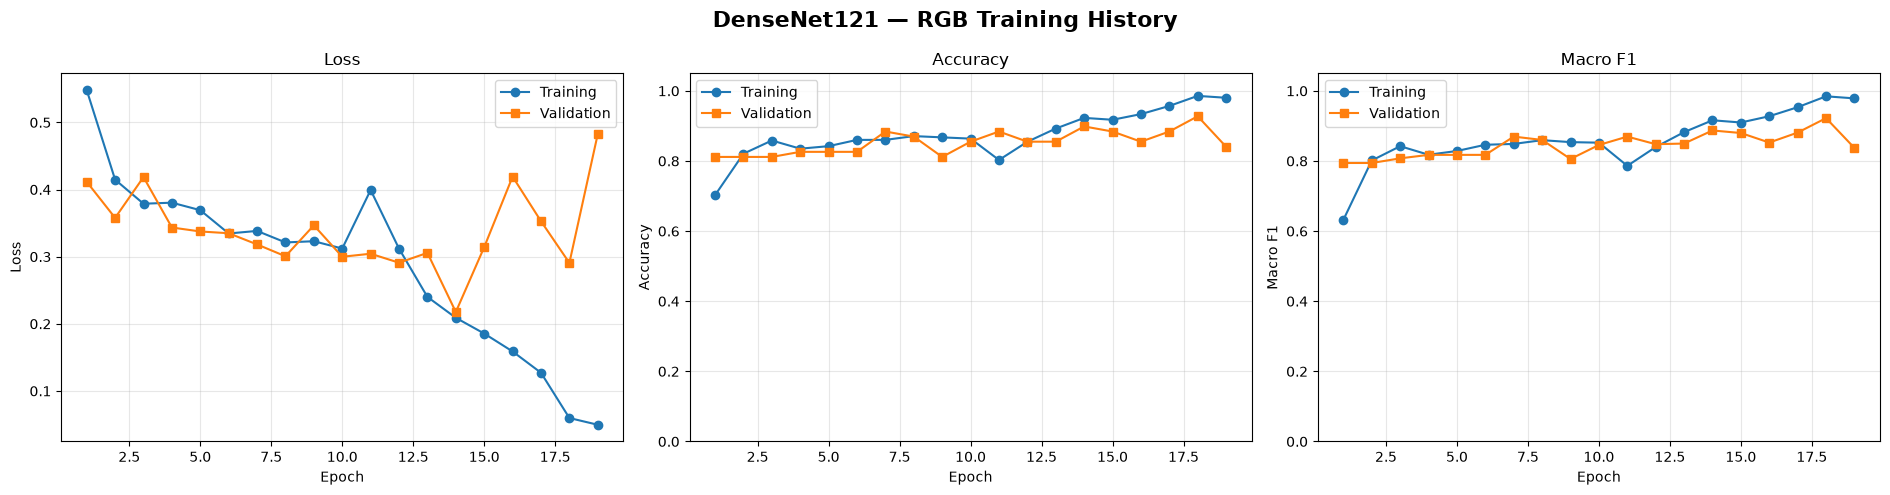

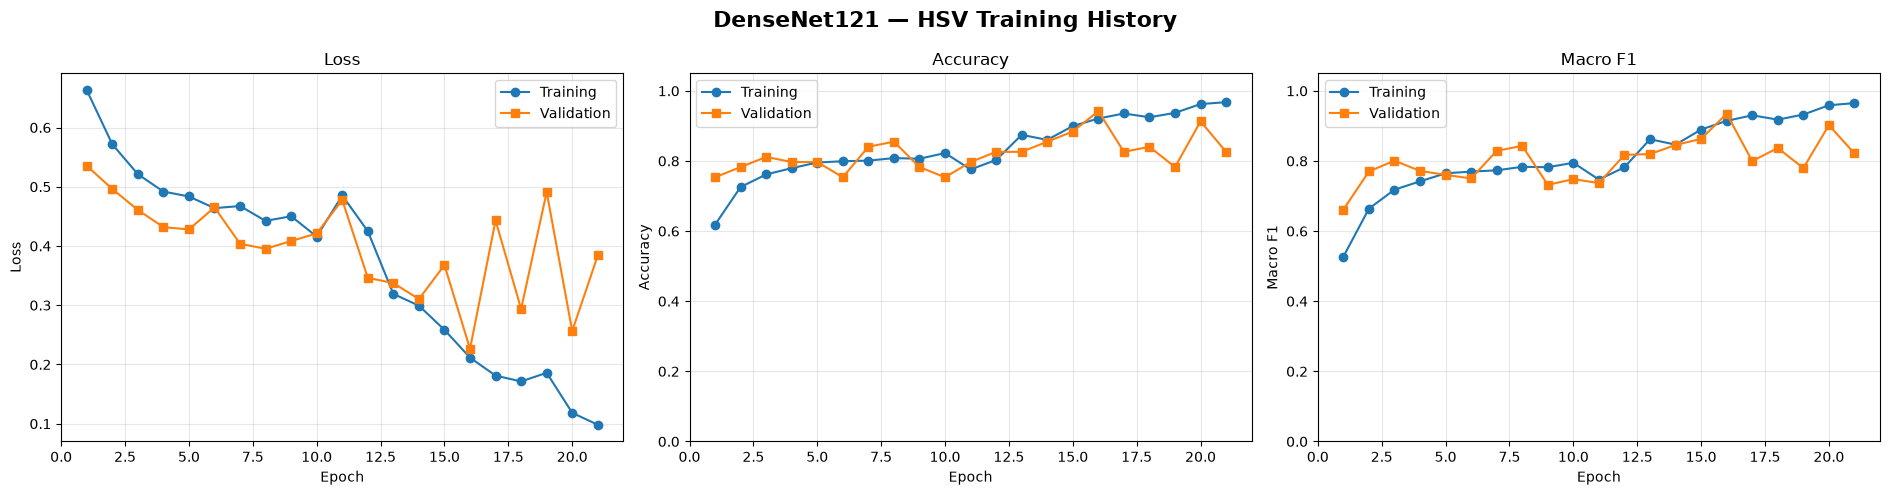

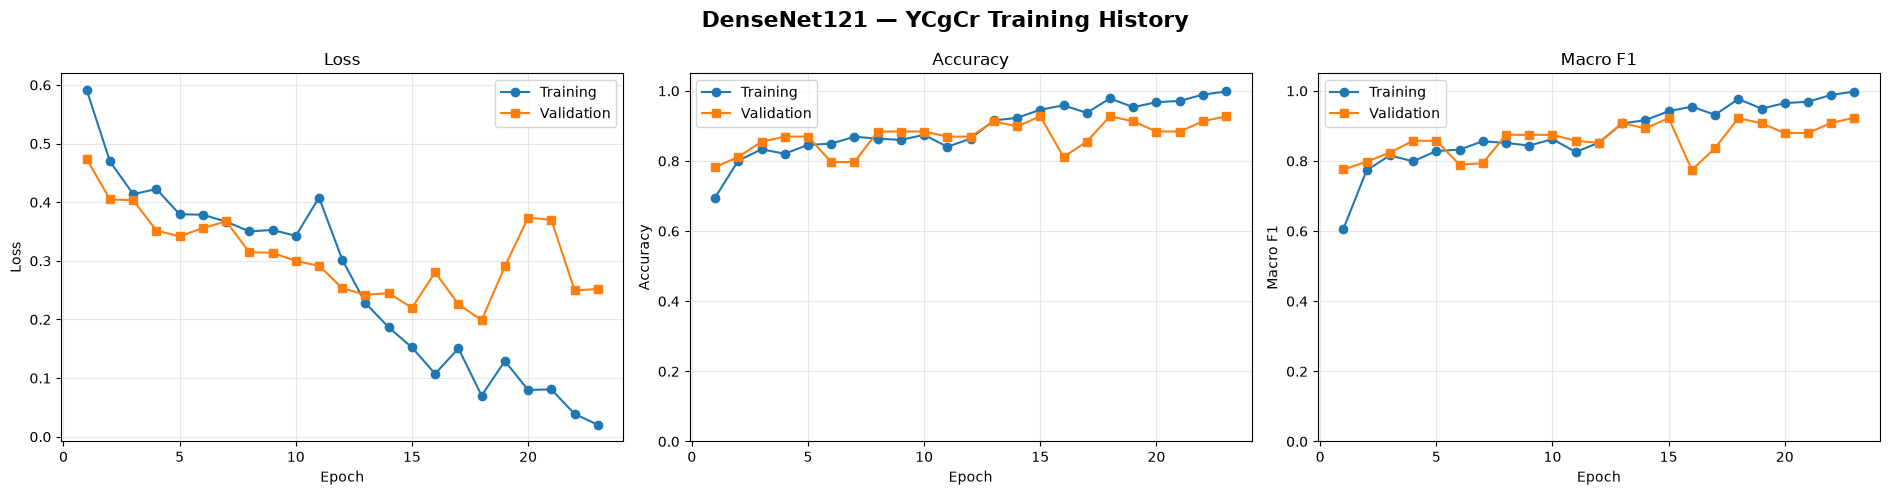

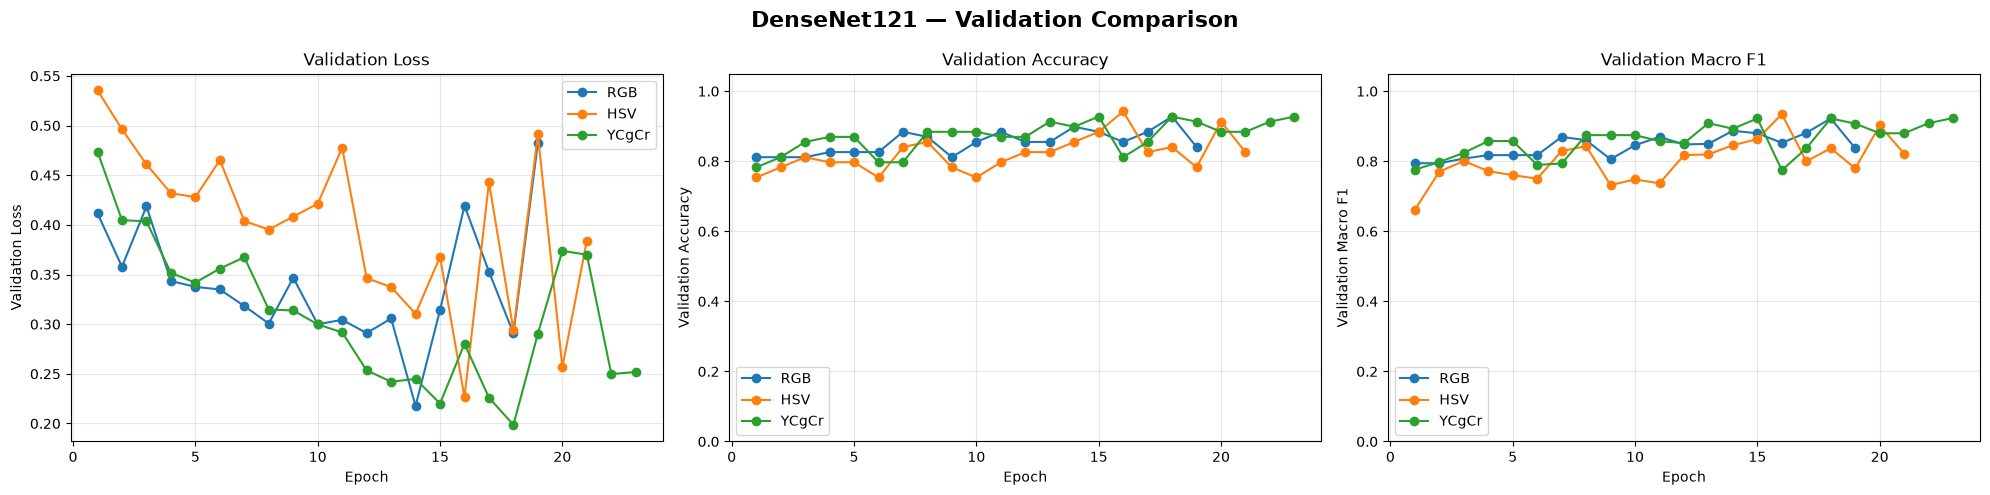

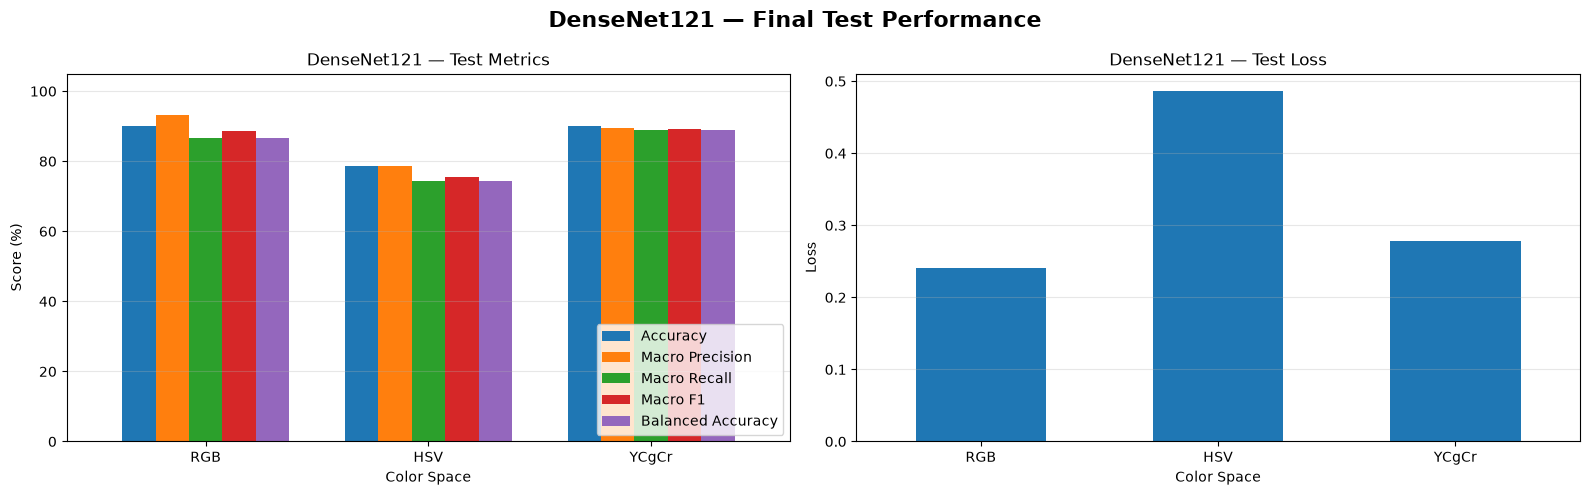

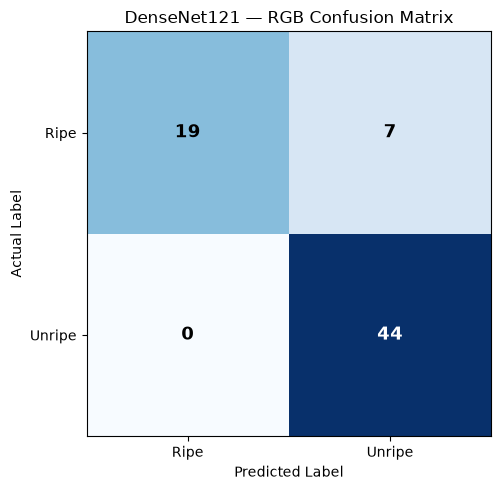

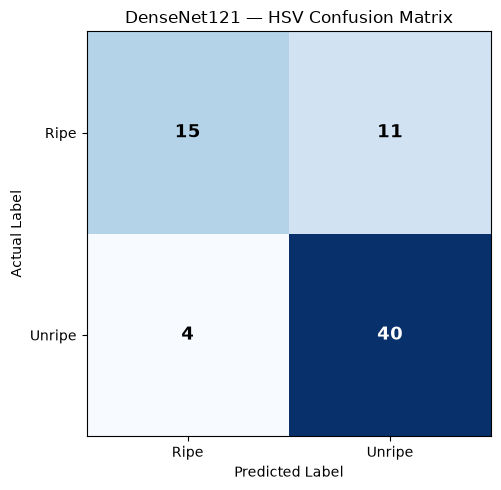

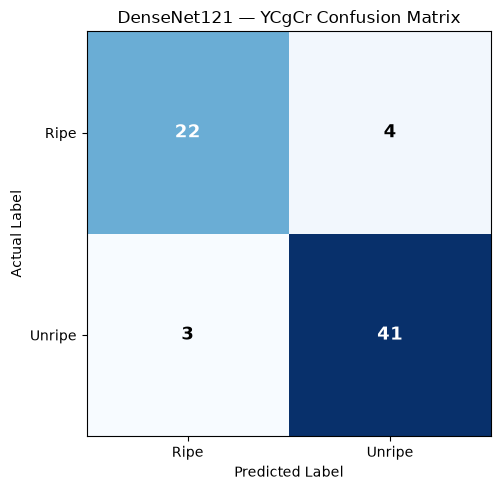

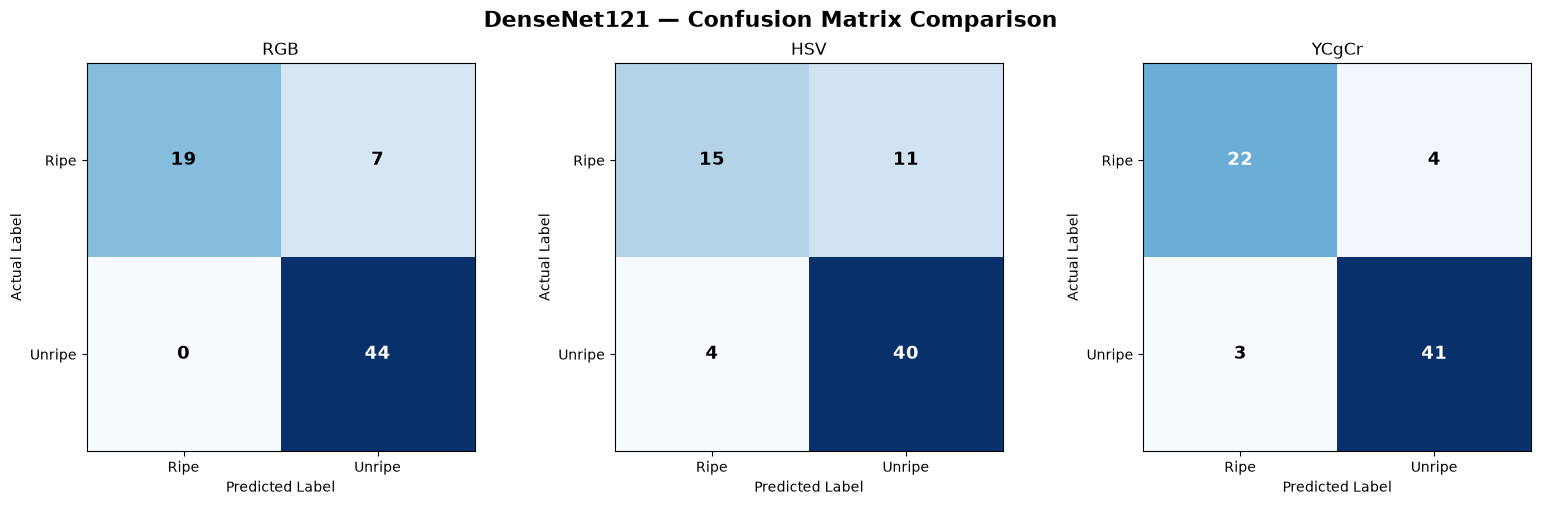


VALIDATION CHECKPOINT COMPARISON


,Color Space,Best Epoch,Best Phase,Validation Loss,Validation Accuracy,Validation Macro F1
0,RGB,14,Phase 2,0.2176,89.8551,0.8871
1,HSV,16,Phase 2,0.2263,94.2029,0.9348
2,YCgCr,18,Phase 2,0.1987,92.7536,0.9222



FINAL TEST RESULTS


,Color Space,Test Samples,Test Loss,Accuracy,Macro Precision,Macro Recall,Macro F1,Balanced Accuracy
0,RGB,70,0.2410,0.9000,0.9314,0.8654,0.8854,0.8654
1,HSV,70,0.4862,0.7857,0.7869,0.7430,0.7544,0.7430
2,YCgCr,70,0.2782,0.9000,0.8956,0.8890,0.8920,0.8890



ALL GRAPHS SAVED SUCCESSFULLY
Output directory: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\models\densenet121\graphs
densenet121_combined_confusion_matrices.png
densenet121_combined_validation.png
densenet121_HSV_confusion_matrix.png
densenet121_HSV_training_history.png
densenet121_RGB_confusion_matrix.png
densenet121_RGB_training_history.png
densenet121_test_performance.png
densenet121_validation_comparison.csv
densenet121_YCgCr_confusion_matrix.png
densenet121_YCgCr_training_history.png


In [21]:

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from pathlib import Path

GRAPH_DIR = MODEL_DIR / "graphs"
GRAPH_DIR.mkdir(parents=True, exist_ok=True)

# Load saved histories and results
densenet_histories = {
    cs: pd.read_csv(
        MODEL_DIR / f"densenet121_{cs}_history.csv"
    )
    for cs in COLOR_SPACES
}

densenet_results_df = pd.read_csv(
    MODEL_DIR / "densenet121_final_test_comparison.csv"
)

densenet_confusion_matrices = {
    cs: np.load(
        MODEL_DIR / f"densenet121_{cs}_confusion_matrix.npy"
    )
    for cs in COLOR_SPACES
}


# ============================================================
# HELPER: CONFUSION MATRIX USING MATPLOTLIB
# ============================================================

def plot_confusion_matrix(ax, cm, title):

    ax.imshow(cm, interpolation="nearest", cmap="Blues")

    ax.set_title(title)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(CLASS_NAMES)
    ax.set_yticklabels(CLASS_NAMES)

    threshold = cm.max() / 2

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):

            ax.text(
                j, i, str(cm[i, j]),
                ha="center",
                va="center",
                color="white" if cm[i, j] > threshold else "black",
                fontsize=13,
                fontweight="bold"
            )


# ============================================================
# 1. INDIVIDUAL TRAINING HISTORY GRAPHS
# ============================================================

for cs, df in densenet_histories.items():

    fig, axes = plt.subplots(1, 3, figsize=(19, 5))

    metrics = [
        ("train_loss", "val_loss", "Loss"),
        ("train_accuracy", "val_accuracy", "Accuracy"),
        ("train_macro_f1", "val_macro_f1", "Macro F1")
    ]

    for ax, (train_col, val_col, title) in zip(axes, metrics):

        ax.plot(
            df["epoch"], df[train_col],
            marker="o", label="Training"
        )

        ax.plot(
            df["epoch"], df[val_col],
            marker="s", label="Validation"
        )

        ax.set_title(title)
        ax.set_xlabel("Epoch")
        ax.set_ylabel(title)
        ax.grid(alpha=0.3)
        ax.legend()

        if title != "Loss":
            ax.set_ylim(0, 1.05)

    fig.suptitle(
        f"DenseNet121 — {cs} Training History",
        fontsize=16,
        fontweight="bold"
    )

    plt.tight_layout()

    fig.savefig(
        GRAPH_DIR / f"densenet121_{cs}_training_history.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


# ============================================================
# 2. COMBINED VALIDATION GRAPHS
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

validation_metrics = [
    ("val_loss", "Validation Loss"),
    ("val_accuracy", "Validation Accuracy"),
    ("val_macro_f1", "Validation Macro F1")
]

for ax, (column, title) in zip(axes, validation_metrics):

    for cs, df in densenet_histories.items():

        ax.plot(
            df["epoch"], df[column],
            marker="o", label=cs
        )

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(title)
    ax.grid(alpha=0.3)
    ax.legend()

    if column != "val_loss":
        ax.set_ylim(0, 1.05)

fig.suptitle(
    "DenseNet121 — Validation Comparison",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

fig.savefig(
    GRAPH_DIR / "densenet121_combined_validation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# 3. TEST PERFORMANCE COMPARISON
# ============================================================

plot_metrics = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "Balanced Accuracy"
]

results_plot = densenet_results_df.set_index("Color Space")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

results_plot[plot_metrics].mul(100).plot(
    kind="bar", ax=axes[0], width=0.75
)

axes[0].set_title("DenseNet121 — Test Metrics")
axes[0].set_ylabel("Score (%)")
axes[0].set_xlabel("Color Space")
axes[0].set_ylim(0, 105)
axes[0].tick_params(axis="x", rotation=0)
axes[0].grid(axis="y", alpha=0.3)
axes[0].legend(loc="lower right")

results_plot["Test Loss"].plot(
    kind="bar", ax=axes[1], width=0.55
)

axes[1].set_title("DenseNet121 — Test Loss")
axes[1].set_ylabel("Loss")
axes[1].set_xlabel("Color Space")
axes[1].tick_params(axis="x", rotation=0)
axes[1].grid(axis="y", alpha=0.3)

fig.suptitle(
    "DenseNet121 — Final Test Performance",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

fig.savefig(
    GRAPH_DIR / "densenet121_test_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# 4. INDIVIDUAL CONFUSION MATRICES
# ============================================================

for cs, cm in densenet_confusion_matrices.items():

    fig, ax = plt.subplots(figsize=(6, 5))

    plot_confusion_matrix(
        ax, cm, f"DenseNet121 — {cs} Confusion Matrix"
    )

    plt.tight_layout()

    fig.savefig(
        GRAPH_DIR / f"densenet121_{cs}_confusion_matrix.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


# ============================================================
# 5. COMBINED CONFUSION MATRICES
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, cs in zip(axes, COLOR_SPACES):

    plot_confusion_matrix(
        ax,
        densenet_confusion_matrices[cs],
        cs
    )

fig.suptitle(
    "DenseNet121 — Confusion Matrix Comparison",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

fig.savefig(
    GRAPH_DIR / "densenet121_combined_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# 6. VALIDATION CHECKPOINT COMPARISON
# ============================================================

checkpoint_rows = []

for cs, df in densenet_histories.items():

    best = df.loc[df["val_loss"].idxmin()]

    checkpoint_rows.append({
        "Color Space": cs,
        "Best Epoch": int(best["epoch"]),
        "Best Phase": best["phase"],
        "Validation Loss": best["val_loss"],
        "Validation Accuracy": best["val_accuracy"] * 100,
        "Validation Macro F1": best["val_macro_f1"]
    })

validation_comparison_df = pd.DataFrame(checkpoint_rows)

validation_comparison_df.to_csv(
    GRAPH_DIR / "densenet121_validation_comparison.csv",
    index=False
)

print("\nVALIDATION CHECKPOINT COMPARISON")
display(validation_comparison_df.round(4))

print("\nFINAL TEST RESULTS")
display(densenet_results_df.round(4))

print("\nALL GRAPHS SAVED SUCCESSFULLY")
print("Output directory:", GRAPH_DIR)

for file in sorted(GRAPH_DIR.iterdir()):
    print(file.name)


In [6]:

# Generate and save DenseNet121 research conclusion

report_path = GRAPH_DIR / "densenet121_research_conclusion.md"

report_path.write_text(
    conclusion.strip(),
    encoding="utf-8"
)

print("DenseNet121 research conclusion saved successfully.")
print("Report:", report_path)


DenseNet121 research conclusion saved successfully.
Report: C:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\models\densenet121\graphs\densenet121_research_conclusion.md


In [7]:
from IPython.display import Markdown, display

display(Markdown(report_path.read_text(encoding="utf-8")))

# DenseNet121 — Experimental Results and Research Conclusion

## 1. Experimental Objective

The objective of this experiment was to evaluate DenseNet121 for
binary arecanut ripeness classification using three input color
representations:

- RGB
- HSV
- Custom YCgCr representation

The same dataset partitions and model-training configuration were
used across the three experiments to support a controlled comparison.

## 2. Dataset and Experimental Configuration

| Parameter | Configuration |
|---|---|
| Model | DenseNet121 |
| Pretrained weights | ImageNet |
| Image size | 224 × 224 |
| Batch size | 16 |
| Optimizer | AdamW |
| Weight decay | 0.0001 |
| Phase 1 learning rate | 0.001 |
| Phase 2 learning rate | 0.0001 |
| Maximum Phase 1 epochs | 10 |
| Maximum Phase 2 epochs | 40 |
| Early stopping patience | 5 |
| Random seed | 42 |
| Number of classes | 2 |

### Dataset partition

| Partition | Ripe | Unripe | Total |
|---|---:|---:|---:|
| Training | 204 | 354 | 558 |
| Validation | 25 | 44 | 69 |
| Testing | 26 | 44 | 70 |
| Total | 255 | 442 | 697 |

The final grouped dataset contains 697 retained images after the
duplicate and label-conflict audit.

## 3. Best Validation Checkpoints

The checkpoint for each color space was selected using minimum
validation loss.

```text
Color Space  Best Epoch Best Phase  Validation Loss  Validation Accuracy  Validation Macro F1
        RGB          14    Phase 2           0.2176               0.8986               0.8871
        HSV          16    Phase 2           0.2263               0.9420               0.9348
      YCgCr          18    Phase 2           0.1987               0.9275               0.9222
```

The selected checkpoints were:

- RGB: Phase 2, overall epoch 14.
- HSV: Phase 2, overall epoch 16.
- YCgCr: Phase 2, overall epoch 18.

## 4. Final Test Results

The selected checkpoints were evaluated on the held-out test set
containing 70 images.

```text
Color Space  Test Samples  Test Loss  Accuracy  Macro Precision  Macro Recall  Macro F1  Balanced Accuracy
        RGB            70     0.2410    0.9000           0.9314        0.8654    0.8854             0.8654
        HSV            70     0.4862    0.7857           0.7869        0.7430    0.7544             0.7430
      YCgCr            70     0.2782    0.9000           0.8956        0.8890    0.8920             0.8890
```

### Best observed test metrics

- Highest test accuracy: RGB
  (90.00%).
- Highest macro F1: YCgCr
  (0.8920).
- Highest balanced accuracy: YCgCr
  (0.8890).
- Lowest test loss: RGB
  (0.2410).

## 5. Comparative Interpretation

RGB and YCgCr both achieved 90.00% test accuracy, while HSV
achieved 78.57%.

Although RGB and YCgCr had identical accuracy, their other
metrics differed. YCgCr achieved the highest macro F1 and
balanced accuracy, indicating a stronger balance between the
two classes in this test evaluation.

RGB achieved the highest macro precision and the lowest test
loss. HSV showed comparatively lower performance across the
reported test metrics.

These findings suggest that the choice of color representation
can influence DenseNet121 classification performance on this
dataset. However, the results do not establish that one color
space will perform best across other datasets or field conditions.

## 6. Training Behavior

Training and validation curves were generated for all three
color spaces.

The training histories show that training performance generally
improved during fine-tuning. Validation performance fluctuated
across epochs, reinforcing the importance of selecting
checkpoints using validation loss rather than simply using the
last training epoch.

The saved training-history graphs should be consulted when
discussing convergence and possible overfitting.

## 7. Research Limitations

The following limitations should be acknowledged:

1. The held-out test set contains only 70 images.
2. The comparison uses one grouped train-validation-test split
   with seed 42.
3. Repeated-seed experiments and statistical significance tests
   have not been established by these results.
4. External validation under different farms, lighting conditions,
   camera devices, and backgrounds has not been demonstrated.
5. The results concern binary image-level classification of
   Ripe and Unripe samples; they do not quantify the maturity
   percentage of individual nuts in a bunch.
6. The experiments compare color representations using
   DenseNet121; they do not establish the performance of
   segmentation or image-fusion methods.

## 8. Conclusion

DenseNet121 was evaluated using RGB, HSV, and custom YCgCr
representations for binary arecanut ripeness classification.

RGB and YCgCr achieved the highest observed test accuracy
of 90.00%. Among these results, YCgCr achieved the highest
macro F1 score of 0.8920 and balanced
accuracy of 0.8890, whereas
RGB achieved the lowest test loss of 0.2410.

HSV achieved a test accuracy of 78.57%.

Overall, YCgCr provided the strongest observed balance between
the two classes for DenseNet121, while RGB also demonstrated
competitive classification performance.

These findings are specific to the current dataset and
experimental split. Further evaluation using repeated
stratified group splits and independent field data is required
before drawing broader conclusions about generalization.

## 9. Generated Graphs

The following visualizations are stored in the graphs directory:

- Individual training-history graphs for RGB, HSV, and YCgCr.
- Combined validation comparison.
- Final test-performance comparison.
- Individual confusion matrices.
- Combined confusion-matrix comparison.
- Validation checkpoint comparison.